In [14]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## A. VISUALISATION DES DONNÉES

1 : Charger le jeu de données et afficher ses informations

In [38]:
df = pd.read_csv('/content/drive/MyDrive/DataMining/titanic_original.csv')

display(df.head(10))

df.info()

df.describe()

,Survie,Chclasse,Sexe,Age,Sibsp,Parch,Ticket,Fare,Cabin,Embarked
0,1,1,female,29.0000,0,0,24160,211.3375,B5,S
1,1,1,male,0.9167,1,2,113781,151.5500,C22 C26,S
2,0,1,female,2.0000,1,2,113781,151.5500,C22 C26,S
3,0,1,male,30.0000,1,2,113781,151.5500,C22 C26,S
4,0,1,female,25.0000,1,2,113781,151.5500,C22 C26,S
5,1,1,male,48.0000,0,0,19952,26.5500,E12,S
6,1,1,female,63.0000,1,0,13502,77.9583,D7,S
7,0,1,male,39.0000,0,0,112050,0.0000,A36,S
8,1,1,female,53.0000,2,0,11769,51.4792,C101,S
9,0,1,male,71.0000,0,0,PC 17609,49.5042,NaN,C


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survie    1309 non-null   int64  
 1   Chclasse  1309 non-null   int64  
 2   Sexe      1309 non-null   object 
 3   Age       1046 non-null   float64
 4   Sibsp     1309 non-null   int64  
 5   Parch     1309 non-null   int64  
 6   Ticket    1309 non-null   object 
 7   Fare      1308 non-null   float64
 8   Cabin     295 non-null    object 
 9   Embarked  1307 non-null   object 
dtypes: float64(2), int64(4), object(4)
memory usage: 102.4+ KB


,Survie,Chclasse,Age,Sibsp,Parch,Fare
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000
mean,0.381971,2.294882,29.881135,0.498854,0.385027,33.295479
std,0.486055,0.837836,14.413500,1.041658,0.865560,51.758668
min,0.000000,1.000000,0.166700,0.000000,0.000000,0.000000
25%,0.000000,2.000000,21.000000,0.000000,0.000000,7.895800
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,39.000000,1.000000,0.000000,31.275000
max,1.000000,3.000000,80.000000,8.000000,9.000000,512.329200


2 : Visualiser les labels des colonnes

In [39]:
print(df.columns)

Index(['Survie', 'Chclasse', 'Sexe', 'Age', 'Sibsp', 'Parch', 'Ticket', 'Fare',
       'Cabin', 'Embarked'],
      dtype='object')


3 : Éliminer les colonnes inutiles (Ticket et Cabin)

In [40]:
df = df.drop(columns=['Ticket', 'Cabin'])
display(df.head())

,Survie,Chclasse,Sexe,Age,Sibsp,Parch,Fare,Embarked
0,1,1,female,29.0000,0,0,211.3375,S
1,1,1,male,0.9167,1,2,151.5500,S
2,0,1,female,2.0000,1,2,151.5500,S
3,0,1,male,30.0000,1,2,151.5500,S
4,0,1,female,25.0000,1,2,151.5500,S


4 : Afficher la colonne Survie de deux façons

In [41]:
print(df['Survie'])

print(df.Survie)

0       1
1       1
2       0
3       0
4       0
       ..
1304    0
1305    0
1306    0
1307    0
1308    0
Name: Survie, Length: 1309, dtype: int64
0       1
1       1
2       0
3       0
4       0
       ..
1304    0
1305    0
1306    0
1307    0
1308    0
Name: Survie, Length: 1309, dtype: int64


5 : Afficher les colonnes Survie et Sexe

In [42]:
display(df[['Survie', 'Sexe']])

,Survie,Sexe
0,1,female
1,1,male
2,0,female
3,0,male
4,0,female
...,...,...
1304,0,female
1305,0,female
1306,0,male
1307,0,male


6 : Sélectionner un segment du jeu de données

In [43]:
display(df.iloc[0:10, 3:5])

display(df.loc[0:10, ['Age', 'Sibsp']])

,Age,Sibsp
0,29.0000,0
1,0.9167,1
2,2.0000,1
3,30.0000,1
4,25.0000,1
5,48.0000,0
6,63.0000,1
7,39.0000,0
8,53.0000,2
9,71.0000,0


,Age,Sibsp
0,29.0000,0
1,0.9167,1
2,2.0000,1
3,30.0000,1
4,25.0000,1
5,48.0000,0
6,63.0000,1
7,39.0000,0
8,53.0000,2
9,71.0000,0


Représentations monodimensionnelles

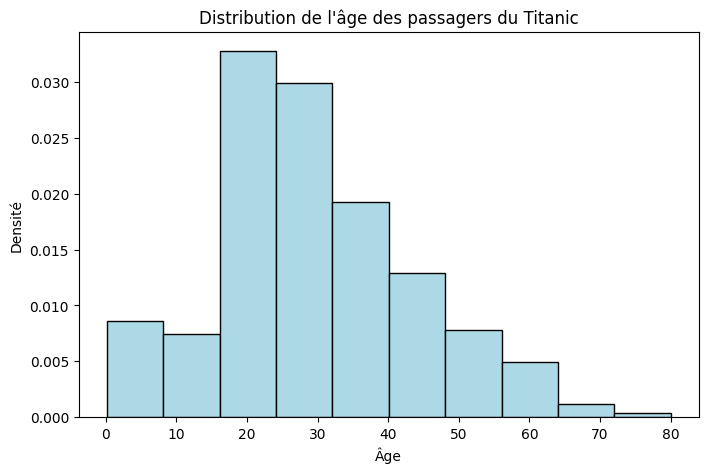

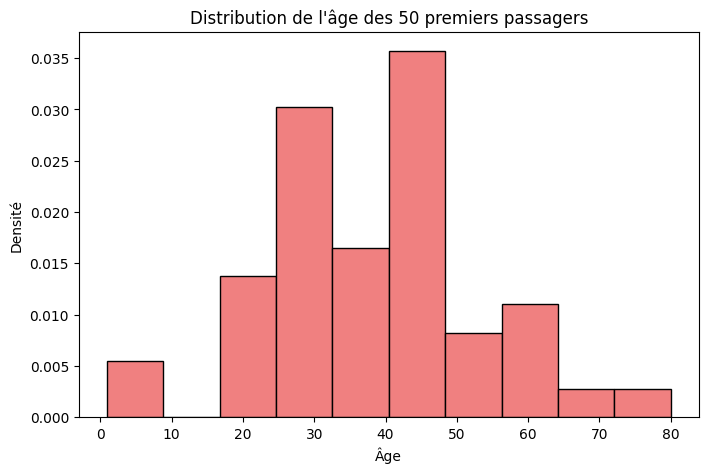

In [44]:
# Histogramme de l'attribut Age
plt.figure(figsize=(8, 5))
plt.hist(df['Age'], density=True, color="lightblue", edgecolor='black')
plt.ylabel("Densité")
plt.xlabel("Âge")
plt.title("Distribution de l'âge des passagers du Titanic")
plt.show()

# Histogramme des 50 premiers passagers
plt.figure(figsize=(8, 5))
plt.hist(df['Age'][:50], density=True, color="lightcoral", edgecolor='black')
plt.ylabel("Densité")
plt.xlabel("Âge")
plt.title("Distribution de l'âge des 50 premiers passagers")
plt.show()

Répartition des sexes

Sexe
male      843
female    466
Name: count, dtype: int64


col_0,count
Sexe,
female,466
male,843


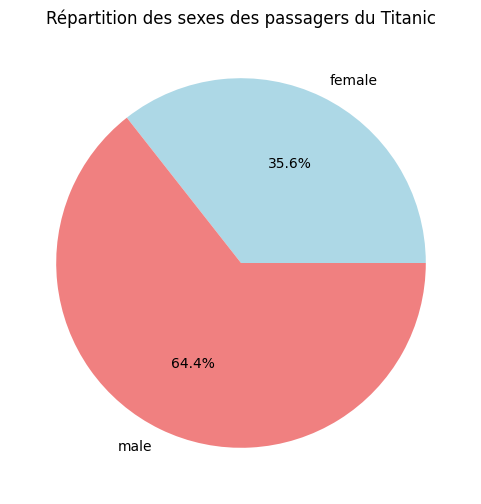

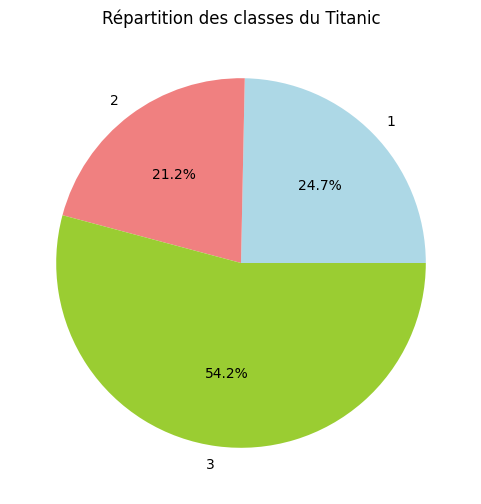

In [45]:
print(df['Sexe'].value_counts())

total = len(df)
# Removed percentage print statements as they contain explanatory text.

tab_sexe = pd.crosstab(index=df['Sexe'], columns="count")
display(tab_sexe)

# Diagramme circulaire (camembert) de la répartition des sexes
plt.figure(figsize=(6, 6))
plt.pie(tab_sexe['count'], labels=tab_sexe.index,
        colors=['lightblue', 'lightcoral'], autopct='%1.1f%%')
plt.title("Répartition des sexes des passagers du Titanic")
plt.show()

# Camembert de la répartition des classes
tab_classe = pd.crosstab(index=df['Chclasse'], columns="count")
plt.figure(figsize=(6, 6))
plt.pie(tab_classe['count'], labels=tab_classe.index,
        colors=['lightblue', 'lightcoral', 'yellowgreen'], autopct='%1.1f%%')
plt.title("Répartition des classes du Titanic")
plt.show()

Représentations bidimensionnelles

Sexe,female,male
Survie,,
0,127,682
1,339,161


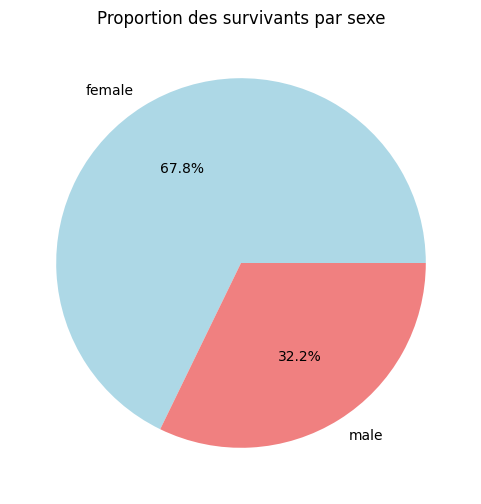

In [46]:
# Table de contingence Survie / Sexe
tab_survie_sexe = pd.crosstab(index=df['Survie'], columns=df['Sexe'])
display(tab_survie_sexe)


y = df[df.Age > 40]
survivants = df[df['Survie'] == 1]
tab_survivants_sexe = pd.crosstab(index=survivants['Sexe'], columns="count")
plt.figure(figsize=(6, 6))
plt.pie(tab_survivants_sexe['count'], labels=tab_survivants_sexe.index,
        colors=['lightblue', 'lightcoral'], autopct='%1.1f%%')
plt.title("Proportion des survivants par sexe")
plt.show()

## B. PRÉPARATION DES DONNÉES

1 : Éliminer les attributs inutiles (Ticket, Cabin)


In [47]:
display(df.head())

,Survie,Chclasse,Sexe,Age,Sibsp,Parch,Fare,Embarked
0,1,1,female,29.0000,0,0,211.3375,S
1,1,1,male,0.9167,1,2,151.5500,S
2,0,1,female,2.0000,1,2,151.5500,S
3,0,1,male,30.0000,1,2,151.5500,S
4,0,1,female,25.0000,1,2,151.5500,S


2 : Discrétisation de l'attribut Age

In [48]:

df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Age'] = df.groupby(['Sexe', 'Chclasse'])['Age'].transform(lambda x: x.fillna(x.mean()))

df['Age'].fillna(df['Age'].mean(), inplace=True)

def discretiser_age(age):
    if age < 18:
        return 'mineur'
    elif age < 35:
        return 'jeune'
    elif age < 60:
        return 'adulte'
    else:
        return 'senior'

df['Age'] = df['Age'].apply(discretiser_age)

display(df.head())
print(df['Age'].value_counts())

/tmp/ipykernel_572/3276977950.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


,Survie,Chclasse,Sexe,Age,Sibsp,Parch,Fare,Embarked
0,1,1,female,jeune,0,0,211.3375,S
1,1,1,male,mineur,1,2,151.5500,S
2,0,1,female,mineur,1,2,151.5500,S
3,0,1,male,jeune,1,2,151.5500,S
4,0,1,female,jeune,1,2,151.5500,S


Age
jeune     771
adulte    344
mineur    154
senior     40
Name: count, dtype: int64


3 : Remplacement des NaN et discrétisation de Fare

In [49]:
df['Fare'] = pd.to_numeric(df['Fare'], errors='coerce')
df['Fare'].fillna(df['Fare'].mean(), inplace=True)

def discretiser_fare(fare):
    if fare < 100:
        return 'bas'
    elif fare < 350:
        return 'moyen'
    else:
        return 'eleve'

df['Fare'] = df['Fare'].apply(discretiser_fare)

display(df.head())
print(df['Fare'].value_counts())

/tmp/ipykernel_572/3020741785.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Fare'].fillna(df['Fare'].mean(), inplace=True)


,Survie,Chclasse,Sexe,Age,Sibsp,Parch,Fare,Embarked
0,1,1,female,jeune,0,0,moyen,S
1,1,1,male,mineur,1,2,moyen,S
2,0,1,female,mineur,1,2,moyen,S
3,0,1,male,jeune,1,2,moyen,S
4,0,1,female,jeune,1,2,moyen,S


Fare
bas      1225
moyen      80
eleve       4
Name: count, dtype: int64


4 : Discrétisation des colonnes restantes

In [50]:

df['Survie'] = df['Survie'].replace({0: 'décédé', 1: 'survivant'})

df['Chclasse'] = df['Chclasse'].replace({
    1: 'première_classe',
    2: 'deuxième_classe',
    3: 'troisième_classe'
})
df['Parch'] = df['Parch'].apply(lambda x: 'seul' if x == 0 else 'en_famille')

df['Sibsp'] = df['Sibsp'].apply(lambda x: 'solitaire' if x == 0 else 'en_groupe')

display(df.head(10))
df.dtypes

,Survie,Chclasse,Sexe,Age,Sibsp,Parch,Fare,Embarked
0,survivant,première_classe,female,jeune,solitaire,seul,moyen,S
1,survivant,première_classe,male,mineur,en_groupe,en_famille,moyen,S
2,décédé,première_classe,female,mineur,en_groupe,en_famille,moyen,S
3,décédé,première_classe,male,jeune,en_groupe,en_famille,moyen,S
4,décédé,première_classe,female,jeune,en_groupe,en_famille,moyen,S
5,survivant,première_classe,male,adulte,solitaire,seul,bas,S
6,survivant,première_classe,female,senior,en_groupe,seul,bas,S
7,décédé,première_classe,male,adulte,solitaire,seul,bas,S
8,survivant,première_classe,female,adulte,en_groupe,seul,bas,S
9,décédé,première_classe,male,senior,solitaire,seul,bas,C


,0
Survie,object
Chclasse,object
Sexe,object
Age,object
Sibsp,object
Parch,object
Fare,object
Embarked,object


## C. EXTRACTION DES RÈGLES D'ASSOCIATION

 1: Installer le package apyori

In [29]:
df = pd.read_csv('/content/drive/MyDrive/DataMining/titanic-1.csv')


In [31]:
!pip install apyori
from apyori import apriori

  Preparing metadata (setup.py) ... done
  Created wheel for apyori: filename=apyori-1.1.2-py3-none-any.whl size=5954 sha256=d33099d45bc389d2ac517c69bc692222efc9457cf828cab5587ef6e02023bad8
  Stored in directory: /root/.cache/pip/wheels/7f/49/e3/42c73b19a264de37129fadaa0c52f26cf50e87de08fb9804af
Successfully built apyori


2 : Charger le package apyori

In [32]:
def df_to_trans(data, prefix_sep='='):
    """Convertit un DataFrame en liste de transactions pour apyori."""
    trans = pd.get_dummies(data, sparse=True, prefix_sep=prefix_sep)
    col = trans.columns
    transactions = []
    for row in trans.itertuples(index=False):
        items = [col[i] for i in range(len(row)) if row[i] == 1]
        transactions.append(items)
    return np.array(transactions, dtype=object)


def run(data, supp, conf, lift, maxlen=10, prefix_sep='='):
    """Lance l'algorithme Apriori et retourne les règles sous forme de DataFrame."""
    if isinstance(data, pd.DataFrame):
        trans = df_to_trans(data, prefix_sep=prefix_sep)
    else:
        trans = data

    results = list(apriori(trans,
                           min_support=supp,
                           min_confidence=conf,
                           min_lift=lift,
                           max_length=maxlen))
    if len(results) > 0:
        rows = []
        for i in results:
            for j in i.ordered_statistics:
                s = pd.Series(j)
                s[4] = i.support
                rows.append(s)
        results_df = pd.DataFrame(rows)
        results_df.columns = ['lhs', 'rhs', 'confidence', 'lift', 'support']
        results_df = results_df[['lhs', 'rhs', 'support', 'confidence', 'lift']]
        results_df['lhs'] = [list(results_df['lhs'][i]) for i in range(len(results_df))]
        results_df['rhs'] = [list(results_df['rhs'][i])[0] for i in range(len(results_df))]
        return results_df
    return pd.DataFrame()


3 : Transformer le jeu de données en transactions

In [51]:
transactions = df_to_trans(df)
for i in range(min(5, len(transactions))):
    print(transactions[i])

['Survie=survivant', 'Chclasse=première_classe', 'Sexe=female', 'Age=jeune', 'Sibsp=solitaire', 'Parch=seul', 'Fare=moyen', 'Embarked=S']
['Survie=survivant', 'Chclasse=première_classe', 'Sexe=male', 'Age=mineur', 'Sibsp=en_groupe', 'Parch=en_famille', 'Fare=moyen', 'Embarked=S']
['Survie=décédé', 'Chclasse=première_classe', 'Sexe=female', 'Age=mineur', 'Sibsp=en_groupe', 'Parch=en_famille', 'Fare=moyen', 'Embarked=S']
['Survie=décédé', 'Chclasse=première_classe', 'Sexe=male', 'Age=jeune', 'Sibsp=en_groupe', 'Parch=en_famille', 'Fare=moyen', 'Embarked=S']
['Survie=décédé', 'Chclasse=première_classe', 'Sexe=female', 'Age=jeune', 'Sibsp=en_groupe', 'Parch=en_famille', 'Fare=moyen', 'Embarked=S']


4 : Lancer l'algorithme Apriori (maxlen=10)

In [56]:
rules_maxlen_10 = run(transactions, supp=0.06, conf=0.75, lift=1.1, maxlen=10)
if not rules_maxlen_10.empty:
    display(rules_maxlen_10.head())

,lhs,rhs,support,confidence,lift
0,[Embarked=Q],Age=jeune,0.077158,0.821138,1.394124
1,[Age=jeune],Parch=seul,0.506494,0.859922,1.123391
2,[Chclasse=deuxième_classe],Embarked=S,0.184874,0.873646,1.251207
3,[Fare=moyen],Chclasse=première_classe,0.061115,1.000000,4.052632
4,[Embarked=Q],Chclasse=troisième_classe,0.086325,0.918699,1.696160


1832


5 : Extraire les règles ayant Survie comme conséquent (maxlen=5)

In [53]:
rules_survie = run(transactions, supp=0.06, conf=0.75, lift=1.1, maxlen=5)

if not rules_survie.empty:
    rules_with_survie = rules_survie[
        rules_survie['rhs'].isin(['Survie=survivant', 'Survie=décédé'])
    ]
    if not rules_with_survie.empty:
        display(rules_with_survie)

,lhs,rhs,support,confidence,lift
9,[Sexe=male],Survie=décédé,0.521008,0.809015,1.309025
16,"[Age=adulte, Sexe=female]",Survie=survivant,0.079450,0.832000,2.178176
18,"[Sexe=male, Age=adulte]",Survie=décédé,0.134454,0.803653,1.300348
45,"[Sexe=male, Age=jeune]",Survie=décédé,0.327731,0.836257,1.353104
65,"[Chclasse=deuxième_classe, Sexe=female]",Survie=survivant,0.071811,0.886792,2.321623
...,...,...,...,...,...
1171,"[Sexe=male, Sibsp=en_groupe, Parch=seul, Fare=...",Survie=décédé,0.065699,0.811321,1.312755
1173,"[Sexe=male, Sibsp=solitaire]",Survie=décédé,0.378151,0.786963,1.572725
1176,"[Sexe=male, Sibsp=solitaire, Fare=bas]",Survie=décédé,0.378151,0.802269,1.576832
1178,"[Sexe=male, Sibsp=solitaire, Parch=seul]",Survie=décédé,0.378151,0.830537,1.384934


6 : Fixer le support à 0.5 et faire varier la confiance

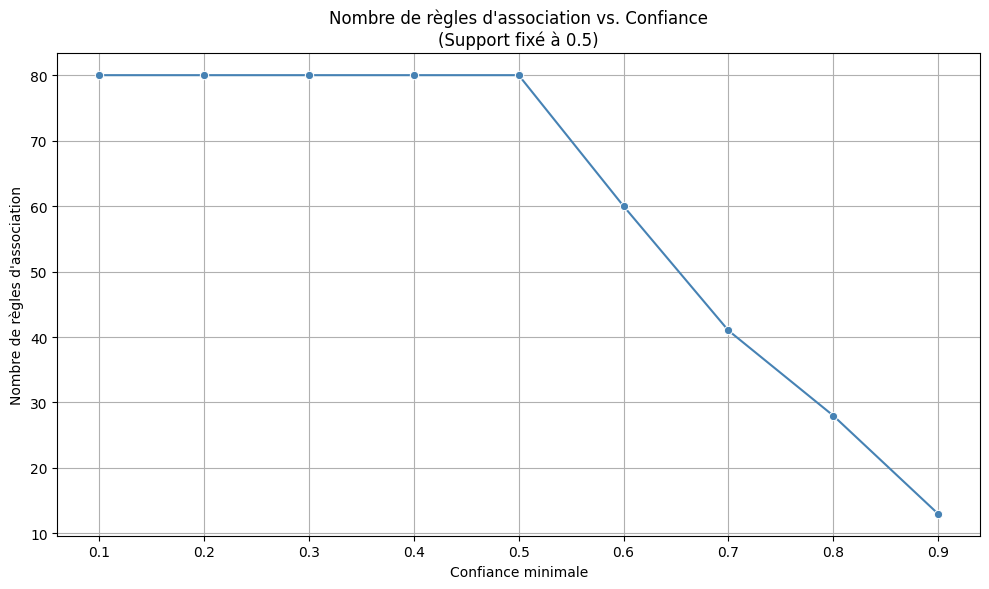

In [54]:
fixed_support = 0.5
confidence_values = np.arange(0.1, 1.0, 0.1)
num_rules_confidence = []

for conf in confidence_values:
    rules = run(transactions, supp=fixed_support, conf=conf, lift=1.0, maxlen=5)
    num_rules_confidence.append(len(rules))

plt.figure(figsize=(10, 6))
sns.lineplot(x=confidence_values, y=num_rules_confidence, marker='o', color='steelblue')
plt.title(f"Nombre de règles d'association vs. Confiance\n(Support fixé à {fixed_support})")
plt.xlabel("Confiance minimale")
plt.ylabel("Nombre de règles d'association")
plt.grid(True)
plt.xticks(np.round(confidence_values, 1))
plt.tight_layout()
plt.show()

Support fixé, confiance varie :
On s'attend à une augmentation du nombre de règles quand la confiance monte (règles plus fiables → plus de combinaisons valides), mais au-delà d'un certain seuil, seules les relations très fortes sont retenues, ce qui peut réduire le nombre de règles.

7 : Fixer la confiance à 0.9 et faire varier le support

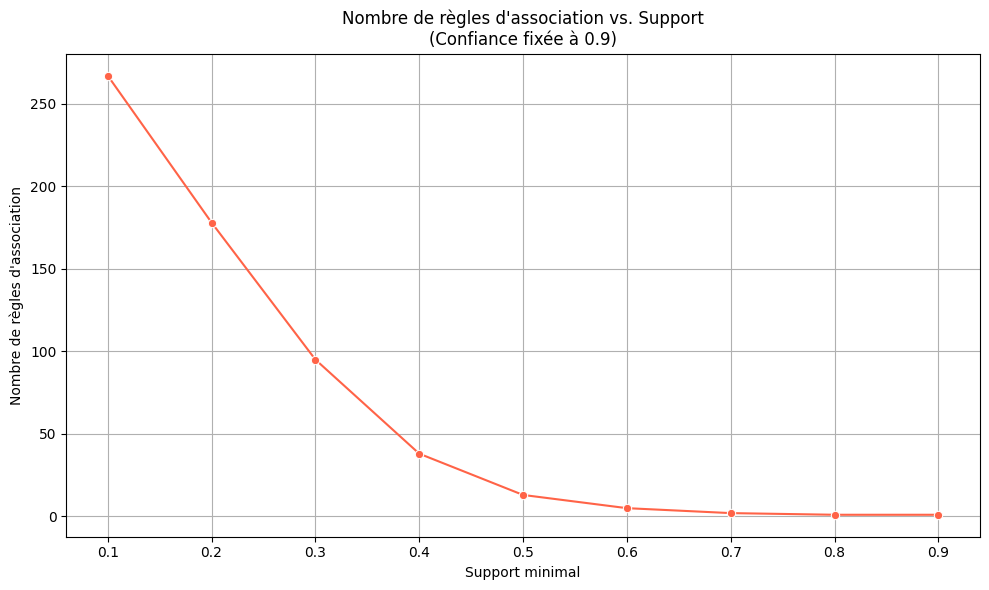

In [55]:
fixed_confidence = 0.9
support_values = np.arange(0.1, 1.0, 0.1)
num_rules_support = []

for supp in support_values:
    rules = run(transactions, supp=supp, conf=fixed_confidence, lift=1.0, maxlen=5)
    num_rules_support.append(len(rules))

plt.figure(figsize=(10, 6))
sns.lineplot(x=support_values, y=num_rules_support, marker='o', color='tomato')
plt.title(f"Nombre de règles d'association vs. Support\n(Confiance fixée à {fixed_confidence})")
plt.xlabel("Support minimal")
plt.ylabel("Nombre de règles d'association")
plt.grid(True)
plt.xticks(np.round(support_values, 1))
plt.tight_layout()
plt.show()

Confiance fixée, support varie :
Un support faible permet à plus de combinaisons d'items d'atteindre le seuil requis → plus de règles extraites. Mais un support trop faible produit des règles moins pertinentes et de moindre qualité.